# Los 97 tiros publicados y las diez campañas de las que provienen

**Pregunta:** ¿Qué campañas contiene el corpus y qué tan desiguales son?

**Nivel 1: Fundamentos** · Requiere: nada, este es el notebook de entrada · Tiempo de lectura: unos 20 minutos

## Objetivos

Fragmenta predice el tamaño medio de fragmento `x50` de una voladura de banco, y luego pregunta cuánto vale esa predicción en una mina que el modelo nunca vio. Todo lo que muestra descansa en una tabla pequeña de mediciones reales, así que este notebook abre la tabla y plantea la pregunta de la que depende el resto del producto: ¿qué campañas contiene y qué tan desiguales son?

Al terminar, usted habrá:

- cargado los 97 tiros con `blastfrag` y leído las siete entradas y el tamaño medido de un registro;
- medido, campaña por campaña, cuántas filas aporta y qué tan gruesa es su fragmentación, y qué parte de la varianza de cada entrada queda entre campañas y no dentro de ellas;
- comparado cada entrada con la envolvente que declara el motor, y con cinco tiros de campo que quedan fuera de ella;
- ejecutado el registro de casos del producto y encontrado cuál de los dieciséis casos no tiene escala conocida.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, agrega al camino de importación la carpeta `data-pipeline/` del producto (allí vive el registro de casos del Paso 5) y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown. El entorno de notebooks no tiene `pandas`, así que el ayudante hace de data frame mostrado.

In [1]:
# Importaciones, versiones fijadas, ruta al pipeline del producto y un ayudante que dibuja una tabla
import json
import sys
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

sys.path.insert(0, str(Path("../../../data-pipeline")))
DERIVED = Path("../../../data/derived")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

Tres fuentes, todas leídas desde archivos o desde el código del propio producto, ninguna escrita a mano:

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| El corpus de entrenamiento de 97 tiros, los dos conjuntos de validación y el conjunto de campo | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el conjunto de campo: tiros de campo de acceso abierto de una mina de granito, tal como los trae el motor) | hechos numéricos reutilizados con cita; el artículo tiene derechos de autor y nunca se distribuye | las tablas dentro del paquete `blastfrag`, leídas por `bf.load_training_corpus()`, `bf.load_holdout()` y `bf.load_field_holdout()` |
| El registro de casos y su cargador | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/registry.py` y `data-pipeline/pipeline/model/blasts.py`, importados por ruta |
| El índice de casos que escribió la ejecución offline | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/manifests/index.json` |

El corpus es adimensional: cada tiro se registra como razones (espaciamiento sobre bordo, altura de banco sobre bordo, bordo sobre diámetro de perforación, taco sobre bordo), un factor de carga, el tamaño de bloque in situ y el módulo de la roca, más el `x50` medido.

## Método

### Paso 1: un registro

`load_training_corpus()` devuelve los 97 tiros como registros `Blast` inmutables. La carga también ejecuta la compuerta de integridad que abre el notebook 03 de este tema: la llamada falla si las filas distribuidas dejan de reproducir los estadísticos que imprime el artículo fuente. Un registro tiene siete entradas, en el orden que usa cada ecuación publicada (`bf.FEATURES`), y el tamaño medio medido `x50_m`, la cantidad que todos los notebooks siguientes intentan predecir. La celda carga el corpus e imprime su primer registro. Fíjese en las unidades: cuatro entradas son razones sin unidad, y en el registro no hay ninguna longitud en metros; el notebook 02 las recupera.

In [2]:
# Cargar los 97 tiros (la compuerta de integridad corre dentro de la llamada) y mostrar el primer registro completo
train = bf.load_training_corpus()
first = train[0]
print(f"tiros cargados: {len(train)}")
rows = [(name, getattr(first, name)) for name in bf.FEATURES]
rows.append(("x50_m", first.x50_m))
show_table(["campo", f"valor de {first.blast_id} ({first.site})"], rows)

tiros cargados: 97


| campo | valor de En1 (Enusa) |
|:---|---:|
| S_over_B | 1.24 |
| H_over_B | 1.33 |
| B_over_D | 27.27 |
| T_over_B | 0.78 |
| Pf_kg_m3 | 0.48 |
| XB_m | 0.58 |
| E_GPa | 60.0 |
| x50_m | 0.37 |

El registro es toda la interfaz del corpus: siete números y una medición, sin nada sobre el equipo de perforación, la marca del explosivo ni la fecha. La tabla muestra además lo poco que dice una fila sobre su origen: aparte de la etiqueta de campaña (`Enusa`), solo el módulo de la roca, una constante del macizo, insinúa dónde se disparó el tiro. Esa etiqueta resulta importar más que cualquier entrada por separado, y el paso siguiente agrupa los 97 registros por ella.

### Paso 2: las diez campañas

Las filas de una misma campaña comparten macizo rocoso, equipo de perforación, suministro de explosivo y equipo de medición, así que no son observaciones independientes de una sola población. Ese es el hecho estructural detrás del producto, fácil de enunciar y fácil de olvidar, y este paso lo vuelve medible. La celda tabula, para cada campaña, el número de filas y el promedio, el mínimo y el máximo del `x50` medido, y luego dibuja dos paneles: la cantidad de filas de cada campaña y el tamaño medido de cada tiro, un punto por tiro, con las campañas ordenadas de la media más fina a la más gruesa. Busque dos cosas: qué tan desiguales son los conteos y si los puntos de una campaña se traslapan con los de las otras.

| campaña | n | parte de las filas | x50 medio (m) | mín | máx |
|:---|---:|---:|---:|---:|---:|
| Reocin | 10 | 10% | 0.616 | 0.44 | 0.96 |
| Reocin-UG | 6 | 6% | 0.593 | 0.51 | 0.69 |
| Dongri-Buzurg | 9 | 9% | 0.413 | 0.23 | 0.76 |
| Enusa | 12 | 12% | 0.396 | 0.26 | 0.64 |
| Murgul | 7 | 7% | 0.311 | 0.23 | 0.38 |
| Soma | 7 | 7% | 0.224 | 0.15 | 0.28 |
| Ozmert | 7 | 7% | 0.191 | 0.12 | 0.30 |
| Akdaglar | 22 | 23% | 0.171 | 0.14 | 0.22 |
| Mrica | 11 | 11% | 0.166 | 0.13 | 0.21 |
| Miami | 6 | 6% | 0.080 | 0.02 | 0.10 |

media de campaña mayor sobre la menor: 7.7


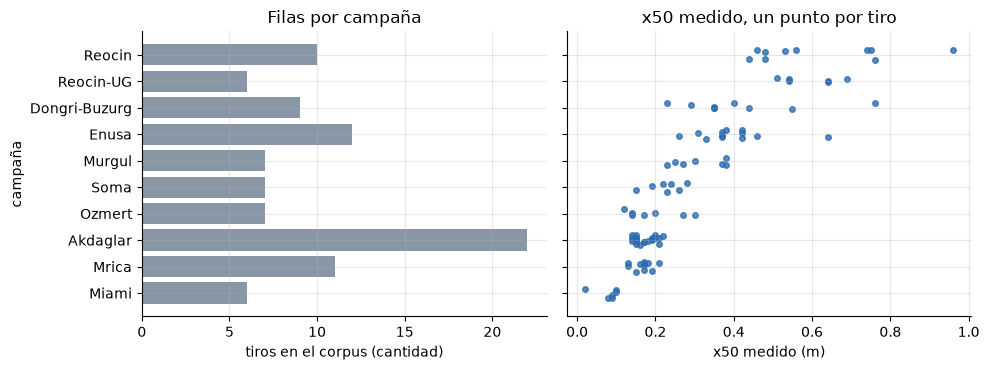

In [3]:
# Tabular cada campaña, ordenada por su tamaño medio, y dibujar su número de filas y el tamaño medido de cada tiro
sites = sorted({b.site for b in train}, key=lambda s: np.mean([b.x50_m for b in train if b.site == s]))
rows = []
for site in sites:
    sizes = np.array([b.x50_m for b in train if b.site == site])
    share = f"{len(sizes) / len(train):.0%}"
    rows.append((site, len(sizes), share, f"{sizes.mean():.3f}", f"{sizes.min():.2f}", f"{sizes.max():.2f}"))
header = ["campaña", "n", "parte de las filas", "x50 medio (m)", "mín", "máx"]
show_table(header, rows[::-1])
means = [float(r[3]) for r in rows]
print(f"media de campaña mayor sobre la menor: {max(means) / min(means):.1f}")

positions = np.arange(len(sites))
rng = np.random.default_rng(0)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
left.barh(positions, [r[1] for r in rows], color="#8896a5")
left.set_xlabel("tiros en el corpus (cantidad)")
left.set_title("Filas por campaña")
for position, site in zip(positions, sites):
    sizes = [b.x50_m for b in train if b.site == site]
    right.scatter(sizes, position + rng.uniform(-0.2, 0.2, len(sizes)), s=16, color="#2b6cb0", alpha=0.8)
right.set_xlabel("x50 medido (m)")
right.set_title("x50 medido, un punto por tiro")
left.set_yticks(positions, sites)
left.set_ylabel("campaña")
fig.tight_layout()
plt.show()

El panel izquierdo muestra el desbalance: Akdaglar por sí sola aporta 22 de las 97 filas, el 23 por ciento, mientras Miami y Reocin-UG aportan 6 cada una. El panel derecho muestra la separación: las medias de campaña van de 0.080 m en Miami a 0.616 m en Reocin, una razón de 7.7, y los puntos de Akdaglar, Mrica y Miami quedan en bandas angostas muy a la izquierda de Reocin y Reocin-UG. Dongri-Buzurg y Enusa se dispersan mucho, así que las campañas también difieren en cuánto varían sus propios tiros. La figura no dice por qué difieren las campañas (roca, diseño o explosivo), ni que los tamaños se puedan predecir a partir de las entradas; dice que una predicción para una campaña nueva no puede apoyarse en filas de esa campaña.

### Paso 3: las entradas por campaña y la envolvente declarada

El motor declara una envolvente de entrenamiento, el rango de cada una de las siete entradas en el corpus (`TRAINING_ENVELOPE`), y rechaza o marca una predicción fuera de ella; `envelope_report` cuenta las filas fuera. Otros dos números dicen cómo se relacionan las campañas con cada entrada: en cuántas campañas la entrada toma un solo valor, y la parte de su varianza que queda entre campañas, calculada como uno menos la suma de cuadrados dentro de cada campaña sobre la suma de cuadrados total (el eta cuadrado de un análisis de varianza de un factor). Una parte cercana al 100 por ciento significa que la campaña casi fija la entrada; una cercana a 0 significa que las campañas son intercambiables en ella. El tamaño medido `x50_m` se agrega como última fila de referencia.

In [4]:
# Para cada entrada: el rango declarado, las filas fuera de él, las campañas con un solo valor y la parte entre campañas
report = bf.envelope_report(train)
rows = []
for name in (*bf.FEATURES, "x50_m"):
    by_site = {s: np.array([getattr(b, name) for b in train if b.site == s]) for s in sites}
    values = np.array([getattr(b, name) for b in train])
    within = sum(((v - v.mean()) ** 2).sum() for v in by_site.values())
    between = 1 - within / ((values - values.mean()) ** 2).sum()
    single = sum(len(set(v)) == 1 for v in by_site.values())
    low, high = bf.TRAINING_ENVELOPE.get(name, (values.min(), values.max()))
    outside = report[name]["n_outside_envelope"] if name in report else "-"
    rows.append((name, f"{low:g} to {high:g}", outside, f"{single} of {len(sites)}", f"{between:.0%}"))
header = ["entrada", "rango declarado", "filas fuera",
          "campañas con un valor", "varianza entre campañas"]
show_table(header, rows)

| entrada | rango declarado | filas fuera | campañas con un valor | varianza entre campañas |
|:---|---:|---:|---:|---:|
| S_over_B | 1 to 1.75 | 0 | 4 of 10 | 57% |
| H_over_B | 1.33 to 6.82 | 0 | 2 of 10 | 85% |
| B_over_D | 17.98 to 39.47 | 0 | 3 of 10 | 70% |
| T_over_B | 0.5 to 4.67 | 0 | 1 of 10 | 84% |
| Pf_kg_m3 | 0.22 to 1.26 | 0 | 1 of 10 | 63% |
| XB_m | 0.02 to 2.35 | 0 | 1 of 10 | 53% |
| E_GPa | 9.57 to 60 | 0 | 10 of 10 | 100% |
| x50_m | 0.02 to 0.96 | - | 0 of 10 | 80% |

Todas las entradas están dentro de la envolvente, lo que no es un hallazgo: la envolvente es el rango del propio corpus, así que cero filas fuera es verdad por construcción (la última fila, el tamaño medido, no tiene envolvente declarada y muestra el rango del corpus). Las columnas informativas son las dos últimas. El módulo de la roca E toma un solo valor en cada una de las diez campañas, así que toda su varianza queda entre campañas: E es una etiqueta de campaña escrita como número. Las razones de altura de banco y de taco la siguen, con 85 y 84 por ciento de su varianza entre campañas, e incluso la entrada menos ligada a la campaña, el tamaño de bloque in situ, tiene 53 por ciento. El tamaño medido está en 80 por ciento. La tabla no dice qué entradas importan para la fragmentación, solo qué tan fuertemente cada una está ligada a su campaña.

La celda siguiente dibuja las mismas siete entradas, un panel cada una, con una fila de puntos por campaña, la envolvente declarada como banda sombreada y los cinco tiros de campo del conjunto de validación como puntos rojos en la fila superior.

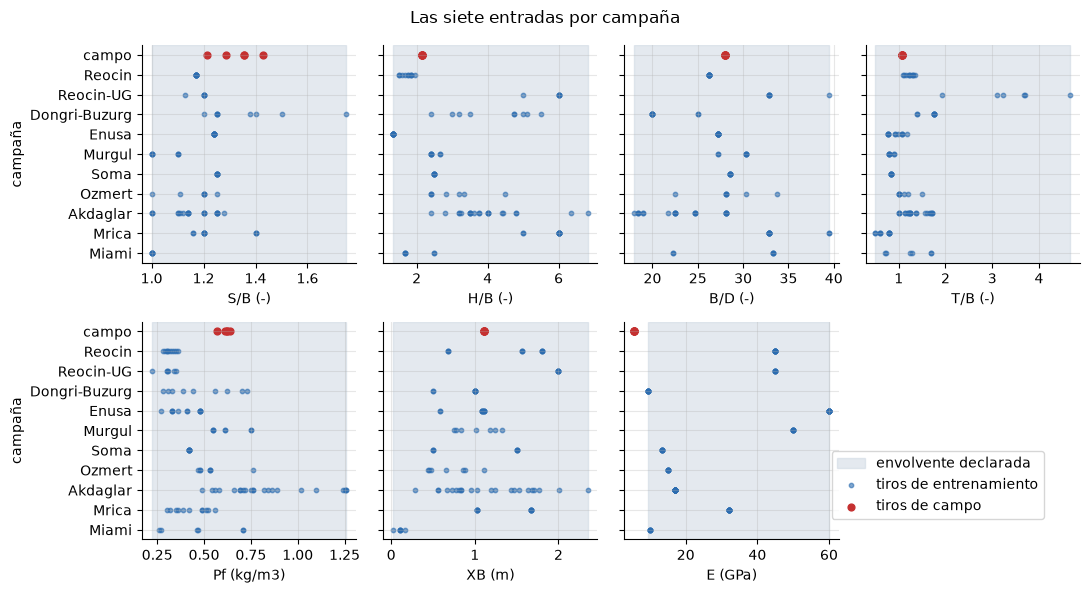

In [5]:
# Un panel por entrada: los tiros de cada campaña, la envolvente declarada como banda y los tiros de campo en rojo
field = bf.load_field_holdout()
units = {"S_over_B": "S/B (-)", "H_over_B": "H/B (-)", "B_over_D": "B/D (-)", "T_over_B": "T/B (-)",
         "Pf_kg_m3": "Pf (kg/m3)", "XB_m": "XB (m)", "E_GPa": "E (GPa)"}
fig, axes = plt.subplots(2, 4, figsize=(11, 6), sharey=True)
for ax, name in zip(axes.flat, bf.FEATURES):
    low, high = bf.TRAINING_ENVELOPE[name]
    ax.axvspan(low, high, color="#cbd5e0", alpha=0.5, label="envolvente declarada")
    for position, site in enumerate(sites):
        values = [getattr(b, name) for b in train if b.site == site]
        label = "tiros de entrenamiento" if position == 0 else None
        ax.scatter(values, [position] * len(values), s=10, color="#2b6cb0", alpha=0.6, label=label)
    extra = [getattr(b, name) for b in field]
    ax.scatter(extra, [len(sites)] * len(extra), s=24, color="#c53030", label="tiros de campo")
    ax.set_xlabel(units[name])
axes[0, 0].set_yticks(range(len(sites) + 1), [*sites, "campo"])
axes[0, 0].set_ylabel("campaña")
axes[1, 0].set_ylabel("campaña")
axes[1, 3].axis("off")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower right", bbox_to_anchor=(0.96, 0.12))
fig.suptitle("Las siete entradas por campaña")
fig.tight_layout()
plt.show()

Cada fila de puntos es una campaña y la banda sombreada es la envolvente declarada. El panel del módulo muestra la estructura de un vistazo: diez columnas verticales, una por campaña, sin nada en medio. Los puntos rojos muestran el caso de extrapolación: los cinco tiros de campo tienen E = 5.6 GPa, a la izquierda de la banda y bajo el mínimo de entrenamiento, mientras sus otras seis entradas quedan dentro. Solo el módulo los vuelve una extrapolación. Lo que la figura no puede mostrar es la estructura conjunta: un tiro puede estar dentro de la banda en cada entrada y aun así ser una combinación inusual, y una banda que es el propio rango del corpus no dice nada sobre qué tan densamente se muestreó.

### Paso 4: los conjuntos de validación

Además de las 97 filas de entrenamiento el motor trae tres conjuntos más: los 13 tiros de la validación del artículo de 2010, los 12 del de 2012 y los cinco tiros de campo. La celda los carga con `load_holdout` y `load_field_holdout` y tabula, para cada conjunto, su tamaño, su rango de módulo, cuántos de sus sitios también son campañas de entrenamiento y cuántas de sus filas también son filas de entrenamiento. Una fila de validación que también es de entrenamiento infla cualquier puntaje, así que el conteo importa antes de que exista un puntaje.

In [6]:
# Los dos conjuntos de validación publicados y el conjunto de campo: tamaño, rango de módulo, sitios y filas compartidos
training_sites = {b.site for b in train}
sets = {"2010": bf.load_holdout(protocol="2010"), "2012": bf.load_holdout(protocol="2012"), "campo": field}
rows = []
for name, blasts in sets.items():
    modulus = [b.E_GPa for b in blasts]
    shared_sites = len({b.site for b in blasts} & training_sites)
    shared_rows = sum(bool(b.meta.get("in_training_table")) for b in blasts)
    rows.append((name, len(blasts), f"{min(modulus):.2f} to {max(modulus):.2f}", shared_sites, shared_rows))
header = ["conjunto", "tiros", "E (GPa)", "sitios también en entrenamiento",
          "filas también en entrenamiento"]
show_table(header, rows)
print("módulo mínimo de entrenamiento (GPa):", min(b.E_GPa for b in train))

| conjunto | tiros | E (GPa) | sitios también en entrenamiento | filas también en entrenamiento |
|:---|---:|---:|---:|---:|
| 2010 | 13 | 9.57 to 60.00 | 9 | 0 |
| 2012 | 12 | 9.57 to 60.00 | 9 | 1 |
| campo | 5 | 5.60 to 5.60 | 0 | 0 |

módulo mínimo de entrenamiento (GPa): 9.57


Los dos conjuntos de validación publicados cubren el mismo rango de módulo que la tabla de entrenamiento, de 9.57 a 60 GPa, así que validan dentro de la envolvente, y nueve de sus sitios son campañas de entrenamiento: una validación publicada de 12 o 13 tiros prueba un modelo en minas que ya vio. Uno de los 12 tiros de 2012 es una fila de entrenamiento, una fuga que los notebooks siguientes mantienen visible. El conjunto de campo tiene un solo módulo, 5.60 GPa, contra un mínimo de entrenamiento de 9.57, y ninguno de sus sitios es una campaña de entrenamiento: es el caso de extrapolación deliberado del producto. La tabla no muestra qué tan difícil es cada conjunto, solo dónde queda respecto de las filas de entrenamiento; el costo de ese traslape es el tema del tema 04.

### Paso 5: los dieciséis casos

El producto no predice para 97 tiros a la vez; los organiza en casos, cada uno un conjunto coherente que responde una pregunta: las campañas reales, el conjunto de campo como control de extrapolación, tres casos de diseño sintético y dos controles. La celda ejecuta el registro del propio producto (`list_cases`) y su cargador (`blasts_for_case`) desde `data-pipeline/`, cuenta los tiros que lleva cada caso y pregunta al motor, con `has_absolute_geometry`, cuántos de ellos tienen escala conocida en metros. Busque el caso que no tiene ninguno.

In [7]:
# Ejecutar el registro de casos del producto: cada caso, los tiros que lleva y cuántos tienen escala conocida
from pipeline.model.blasts import blasts_for_case
from pipeline.registry import category_label, list_cases

rows = []
for case in list_cases():
    blasts = blasts_for_case(case)
    scaled = sum(bf.has_absolute_geometry(b) for b in blasts)
    rows.append((case.id, category_label(case.category)[1], len(blasts), scaled))
header = ["caso", "categoría", "tiros", "con escala conocida"]
show_table(header, rows, left=2)
print("casos:", len(rows))

| caso | categoría | tiros | con escala conocida |
|:---|:---|---:|---:|
| real-enusa | Campanas reales | 12 | 12 |
| real-reocin | Campanas reales | 10 | 10 |
| real-reocin-ug | Campanas reales | 6 | 6 |
| real-murgul | Campanas reales | 7 | 7 |
| real-mrica | Campanas reales | 11 | 11 |
| real-soma | Campanas reales | 7 | 7 |
| real-dongri-buzurg | Campanas reales | 9 | 9 |
| real-akdaglar | Campanas reales | 22 | 22 |
| real-ozmert | Campanas reales | 7 | 7 |
| real-miami | Controles negativos | 6 | 0 |
| real-granite-ne | Control de extrapolacion | 5 | 5 |
| synth-sweep-burden | Barridos de parametros | 12 | 12 |
| synth-sweep-powder | Barridos de parametros | 12 | 12 |
| synth-ibsd-capped | Control estructural | 12 | 12 |
| ctrl-degenerate | Controles negativos | 6 | 6 |
| ctrl-oracle | Control positivo | 8 | 8 |

casos: 16


Nueve casos de campañas reales llevan 91 de los 97 tiros del corpus, y cada uno de sus tiros tiene escala conocida. La décima campaña, Miami, es el caso que no tiene ninguna: 0 de sus 6 tiros, porque la fuente no publica diámetro de perforación ni longitud alguna, así que el motor no puede convertir sus razones en metros y todo predictor que necesite un volumen debe abstenerse allí. Los casos sintéticos son diseños disparados en papel, con un diámetro de perforación que eligió este producto, y los dos controles existen para probar el arnés: un conjunto de diseños que no son tiros y un oráculo. La tabla enumera lo que existe; todavía no dice nada sobre cómo puntúa cada caso, lo que empieza en el tema 04.

### Verificación de reproducción: el registro y el índice versionado

La ejecución offline escribió `data/derived/manifests/index.json`, la lista de casos que muestra el workbench web, a partir del mismo registro que corrió la celda anterior, así que ambos deben nombrar los mismos casos. Esta es la única verificación de reproducción del notebook; la paridad de los números dentro de cada artefacto corresponde a las pruebas del producto.

In [8]:
# Los ids de caso del registro frente al índice que versionó la ejecución offline
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
committed_ids = sorted(case["case_id"] for case in index["cases"])
print("mismos ids de caso en ambos:", committed_ids == sorted(case.id for case in list_cases()))
print("casos en el índice versionado:", len(committed_ids))

mismos ids de caso en ambos: True
casos en el índice versionado: 16


El registro y el índice versionado nombran los mismos 16 casos, así que lo que muestra el workbench web es lo que este notebook acaba de ejecutar. La verificación confirma que las dos listas coinciden; no dice nada sobre los números dentro de ningún caso.

## Resultados

**Respuesta:** El corpus tiene 97 tiros de diez campañas, y las campañas son muy desiguales. Difieren en tamaño, de 22 filas en Akdaglar a 6 en Miami y en Reocin-UG; en resultado, con tamaños medios de campaña de 0.080 m a 0.616 m, una razón de 7.7; y en naturaleza, pues el 80 por ciento de la varianza del tamaño medido y el 100 por ciento de la varianza del módulo de la roca quedan entre campañas y no dentro de ellas.

**Qué se sigue.** Una partición aleatoria de estas filas pondría tiros de una misma campaña a ambos lados de la partición, y un modelo podría puntuar bien reconociendo la campaña por su módulo en vez de aprender fragmentación. Por eso el producto deja fuera campañas completas (tema 04), por eso los cinco tiros de campo con 5.60 GPa se conservan como caso de extrapolación, y por eso la única campaña sin escala conocida, Miami, debe ser rechazada por todo predictor que necesite un volumen.

**Lo que este notebook no muestra.** No predice nada ni puntúa nada. La verificación de la envolvente es verdadera por construcción, porque la envolvente es el propio rango del corpus. La parte entre campañas dice qué tan ligada está una entrada a su campaña, no cuánto importa para la fragmentación. Y si las filas distribuidas coinciden con el artículo fuente es la pregunta del notebook 03 de este tema.

## Resumen

- `load_training_corpus()` devuelve 97 registros de siete entradas y un tamaño medido, y los contrasta con el artículo al cargar.
- Las diez campañas son desiguales en filas (de 22 a 6) y en tamaño medio (de 0.080 a 0.616 m), y el módulo E toma un valor por campaña.
- Toda entrada está dentro de la envolvente declarada porque la envolvente es el rango del corpus; los cinco tiros de campo con 5.60 GPa quedan fuera.
- El registro del producto tiene 16 casos, y la campaña de Miami es la que no tiene escala conocida en metros.
- Siguiente: el notebook 02 convierte las razones en metros, que la ecuación clásica necesita.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus de 97 tiros y el primer conjunto de validación)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el segundo conjunto de validación)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/